In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Basketball Game Analysis Using YOLO26

## End-to-End Object Detection Project

### Project Overview
This project focuses on fine-tuning a pretrained YOLO26
model for basketball game object detection.

### Dataset
- Source: Roboflow
- Total Images: 8,452
- Total Annotations: 34,443
- Number of Classes: 6
- Train Split: 80%
- Validation Split: 10%
- Test Split: 10%

### Project Pipeline
1. Dataset Loading
2. Exploratory Data Analysis (EDA)
3. Data Quality Assessment
4. YOLO26 Fine-Tuning
5. Model Evaluation
6. Prediction Visualization
7. Streamlit Deployment

In [26]:
%pip install -q "ultralytics==8.4.220" roboflow "pillow>=10,<13" lap

Note: you may need to restart the kernel to use updated packages.


## 2. Dataset Loading

The basketball detection dataset is loaded from Roboflow,
with predefined training, validation, and test splits.

In [ ]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

api_key = UserSecretsClient().get_secret(
    "ROBOFLOW_API_KEY"
)

rf = Roboflow(api_key=api_key)

project = rf.workspace("mai-g3jvi").project(
    "basketball-game-detections-sp8yz"
)

dataset = project.version(1).download("yolov8")
                

## 3. Dataset Exploration & Validation

Before fine-tuning YOLO26, we examine the dataset structure,
verify the train/validation/test splits, and inspect the
class definitions to ensure the data is ready for training.

In [4]:
from pathlib import Path
from collections import Counter
import yaml

dataset_path = Path(dataset.location)

with open(dataset_path / "data.yaml", "r") as f:
    data_config = yaml.safe_load(f)

class_names = data_config["names"]

if isinstance(class_names, dict):
    class_names = [
        class_names[k] for k in sorted(class_names, key=int)
    ]

print("Classes:", class_names)
print("Number of Classes:", len(class_names))

splits = {}

for split in ["train", "valid", "test"]:
    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labels = list(labels_dir.glob("*.txt"))

    splits[split] = len(images)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label Files:", len(labels))

total_images = sum(splits.values())

print("\nTotal Images:", total_images)

for split, count in splits.items():
    print(f"{split}: {count / total_images * 100:.1f}%")

Classes: ['Ball', 'FG Attempt', 'FG Made', 'Hoop', 'Player', 'Ref']
Number of Classes: 6

TRAIN
Images: 6762
Label Files: 6762

VALID
Images: 845
Label Files: 845

TEST
Images: 845
Label Files: 845

Total Images: 8452
train: 80.0%
valid: 10.0%
test: 10.0%


### 3.1 Class Distribution Analysis

We analyze the number of annotated objects per class across
the training, validation, and test sets.

This analysis helps identify class imbalance and verify
whether all classes are sufficiently represented in each split.

,train,valid,test,Total
Ball,6653,769,761,8183
FG Attempt,1479,157,162,1798
FG Made,358,35,45,438
Hoop,4544,530,592,5666
Player,14504,2056,1682,18242
Ref,0,103,11,114


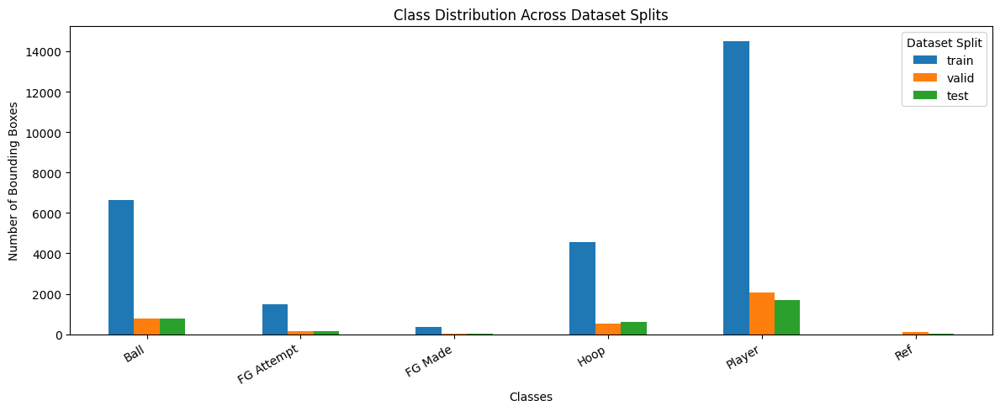

In [5]:
## 4. Dataset Cleaning & Validation

Before training, we validate image-label pairs, check annotation
integrity, detect duplicate images across dataset splits, and
address class distribution issues.

## 4. Dataset Cleaning & Validation

Before training, we validate image-label pairs, check annotation
integrity, detect duplicate images across dataset splits, and
address class distribution issues.

In [10]:
import hashlib
from collections import defaultdict
from PIL import Image

image_hashes = defaultdict(list)
missing_labels = []
invalid_labels = []
corrupted_images = []

for split in ["train", "valid", "test"]:

    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    for img in images_dir.iterdir():

        if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        label = labels_dir / f"{img.stem}.txt"

        # Check image integrity
        try:
            with Image.open(img) as im:
                im.verify()
        except Exception:
            corrupted_images.append(str(img))

        # Check duplicate images
        img_hash = hashlib.md5(img.read_bytes()).hexdigest()
        image_hashes[img_hash].append((split, img.name))

        # Check matching label
        if not label.exists():
            missing_labels.append(str(img))
            continue

        # Validate annotations
        for line in label.read_text().splitlines():

            if not line.strip():
                continue

            try:
                values = line.split()

                if len(values) != 5:
                    raise ValueError()

                cls = int(values[0])
                x, y, w, h = map(float, values[1:])

                if not (
                    0 <= cls < len(class_names)
                    and 0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                ):
                    raise ValueError()

            except ValueError:
                invalid_labels.append(str(label))

duplicates = [
    group for group in image_hashes.values()
    if len(group) > 1
]

cross_split_duplicates = [
    group for group in duplicates
    if len({split for split, _ in group}) > 1
]

print("Missing Labels:", len(missing_labels))
print("Invalid Label Files:", len(set(invalid_labels)))
print("Corrupted Images:", len(corrupted_images))
print("Duplicate Groups:", len(duplicates))
print("Cross-Split Duplicate Groups:", len(cross_split_duplicates))

Missing Labels: 0
Invalid Label Files: 0
Corrupted Images: 0
Duplicate Groups: 0
Cross-Split Duplicate Groups: 0


In [9]:
# Convert polygon annotations to YOLO bounding boxes

corrected = 0

for file in sorted(set(invalid_labels)):
    path = Path(file)
    updated_lines = []

    for line in path.read_text().splitlines():
        values = line.strip().split()

        if not values:
            continue

        if len(values) >= 7 and len(values) % 2 == 1:
            class_id = values[0]

            coords = list(map(float, values[1:]))

            xs = coords[0::2]
            ys = coords[1::2]

            x_min, x_max = min(xs), max(xs)
            y_min, y_max = min(ys), max(ys)

            x_center = (x_min + x_max) / 2
            y_center = (y_min + y_max) / 2
            width = x_max - x_min
            height = y_max - y_min

            line = (
                f"{class_id} {x_center:.8f} "
                f"{y_center:.8f} {width:.8f} "
                f"{height:.8f}"
            )

            corrected += 1

        updated_lines.append(line)

    path.write_text("\n".join(updated_lines) + "\n")

print("Converted Polygon Annotations:", corrected)

Converted Polygon Annotations: 0


## 5. Class Filtering

In [14]:
# Remove referee annotations

removed = 0

if "Ref" in class_names:
    ref_id = class_names.index("Ref")
    assert ref_id == len(class_names) - 1

    for split in ["train", "valid", "test"]:
        for label in (dataset_path / split / "labels").glob("*.txt"):

            lines = label.read_text().splitlines()

            filtered = [
                line for line in lines
                if line.strip()
                and int(line.split()[0]) != ref_id
            ]

            removed += sum(
                1 for line in lines
                if line.strip()
                and int(line.split()[0]) == ref_id
            )

            label.write_text("\n".join(filtered))

    class_names.remove("Ref")

data_config["names"] = class_names
data_config["nc"] = len(class_names)

with open(dataset_path / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Removed Annotations:", removed)
print("Final Classes:", class_names)
print("Number of Classes:", len(class_names))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Removed Annotations: 114
Final Classes: ['Ball', 'FG Attempt', 'FG Made', 'Hoop', 'Player']
Number of Classes: 5


## 6. Dataset Visualization

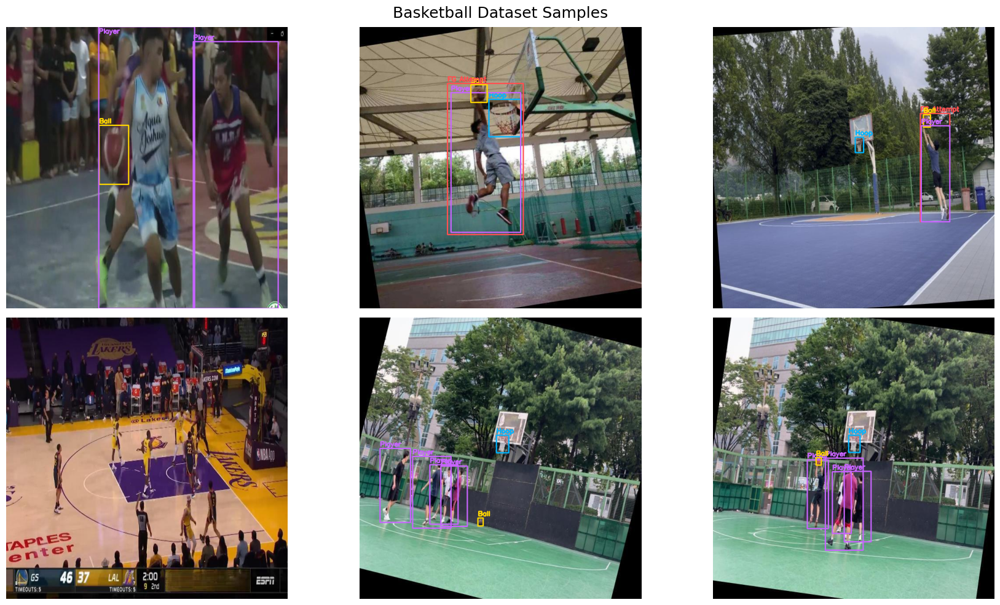

In [15]:
import random
import cv2
import matplotlib.pyplot as plt

# Visualize annotated training samples

random.seed(42)

images_dir = dataset_path / "train" / "images"
labels_dir = dataset_path / "train" / "labels"

image_files = sorted([
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

samples = random.sample(image_files, 6)

colors = [
    (255, 215, 0),
    (255, 80, 80),
    (0, 255, 100),
    (0, 180, 255),
    (200, 100, 255)
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, image_path in zip(axes.flat, samples):

    image = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    h, w = image.shape[:2]

    label_path = labels_dir / f"{image_path.stem}.txt"

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        cls, x, y, bw, bh = map(float, line.split())
        cls = int(cls)

        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)

        color = colors[cls]

        cv2.rectangle(
            image, (x1, y1), (x2, y2), color, 2
        )

        cv2.putText(
            image,
            class_names[cls],
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            color,
            2
        )

    ax.imshow(image)
    ax.axis("off")

plt.suptitle("Basketball Dataset Samples", fontsize=18)
plt.tight_layout()
plt.show()

## 7. Model Fine-Tuning

Fine-tune a pretrained YOLO26s model on the basketball dataset
to detect five object classes using GPU acceleration,
early stopping, and moderate data augmentation.

In [17]:
from ultralytics import YOLO

# Configure dataset paths
data_config.update({
    "path": str(dataset_path.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images"
})

with open(dataset_path / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Load pretrained model
model = YOLO("yolo26s.pt")

# Fine-tune on basketball dataset
results = model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    patience=15,
    optimizer="auto",
    pretrained=True,
    amp=True,
    workers=2,
    seed=42,
    mosaic=0.5,
    mixup=0.0,
    close_mosaic=10,
    plots=True,
    save=True,
    project="/kaggle/working/basketball",
    name="yolo26s_finetuned"
)

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Basketball-Game-Detections-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo26s_finetuned, nbs=64, nms=No

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      5.88G      1.377      1.158    0.01541         41        640: 100% ━━━━━━━━━━━━ 423/423 4.4it/s 1:360.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.8it/s 7.0s0.3s
                   all        845       3549      0.846      0.661      0.755      0.476

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      5.88G      1.396      1.106    0.01579         35        640: 100% ━━━━━━━━━━━━ 423/423 4.4it/s 1:360.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.9it/s 6.9s0.3s
                   all        845       3549      0.869      0.659      0.794      0.503

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      5.88G      1.371      1.062    0.01549         64        640: 100% ━━━━━━━━━━━━ 423/423 4.4it/s 1:360.2sss
                 Class     Ima

## 8. Model Evaluation

Evaluate the best-performing model on the held-out test set
using Precision, Recall, F1-Score, mAP50, and mAP50-95.

In [18]:
# Evaluate the best model on the test set

best_model = YOLO(
    str(results.save_dir / "weights" / "best.pt")
)

test_metrics = best_model.val(
    data=str(dataset_path / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/kaggle/working/basketball",
    name="test_evaluation"
)

# Summarize evaluation metrics

evaluation = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-Score (Macro)",
        "mAP50",
        "mAP50-95"
    ],
    "Score (%)": [
        test_metrics.box.mp * 100,
        test_metrics.box.mr * 100,
        test_metrics.box.f1.mean() * 100,
        test_metrics.box.map50 * 100,
        test_metrics.box.map * 100
    ]
})

display(evaluation.round(2))

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1264.7±444.6 MB/s, size: 48.8 KB)
val: Scanning /kaggle/working/Basketball-Game-Detections-1/test/labels... 845 images, 13 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 845/845 1.1Kit/s 0.8s0.1s
val: New cache created: /kaggle/working/Basketball-Game-Detections-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 3.8it/s 14.0s0.2s
                   all        845       3242      0.955      0.971       0.98      0.827
                  Ball        651        761      0.955      0.976      0.976      0.798
            FG Attempt        160        162      0.914      0.963      0.983      0.838
               FG Made         45         45      0.977      0.978      0.994      0.852
                

,Metric,Score (%)
0,Precision,95.53
1,Recall,97.12
2,F1-Score (Macro),96.31
3,mAP50,98.00
4,mAP50-95,82.67


## 9. Performance Visualization

Visualize training curves, the confusion matrix,
and the precision-recall curve to analyze model performance.


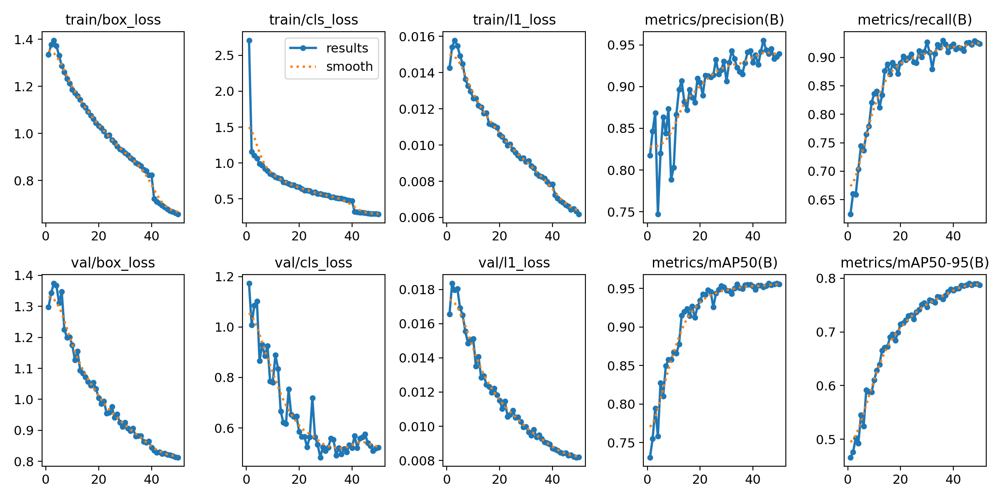

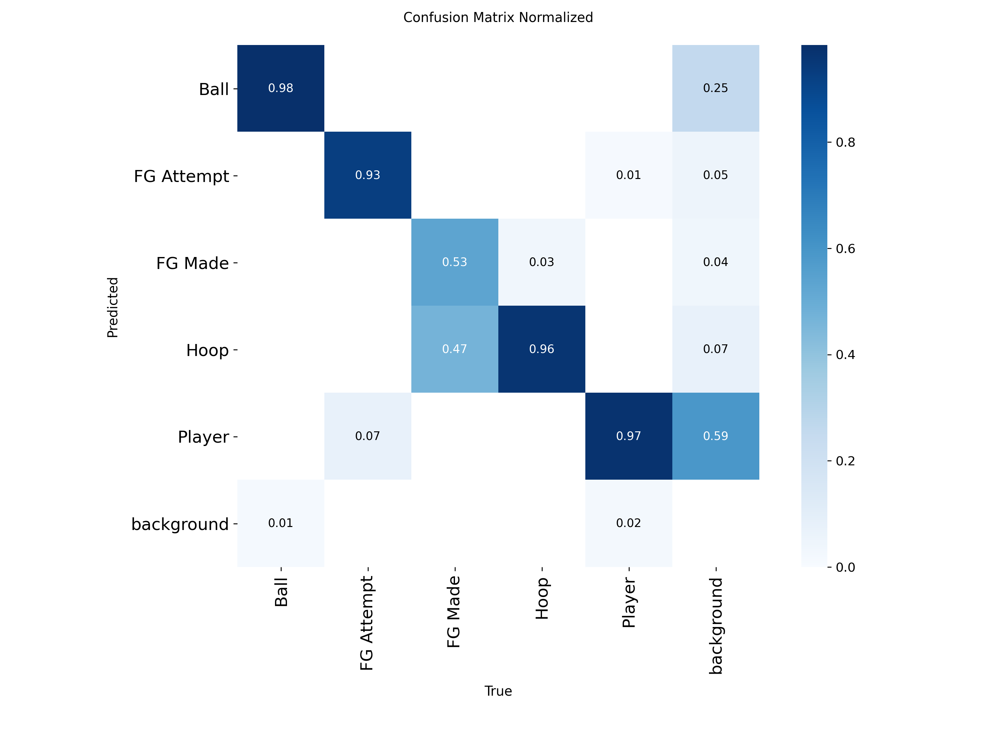

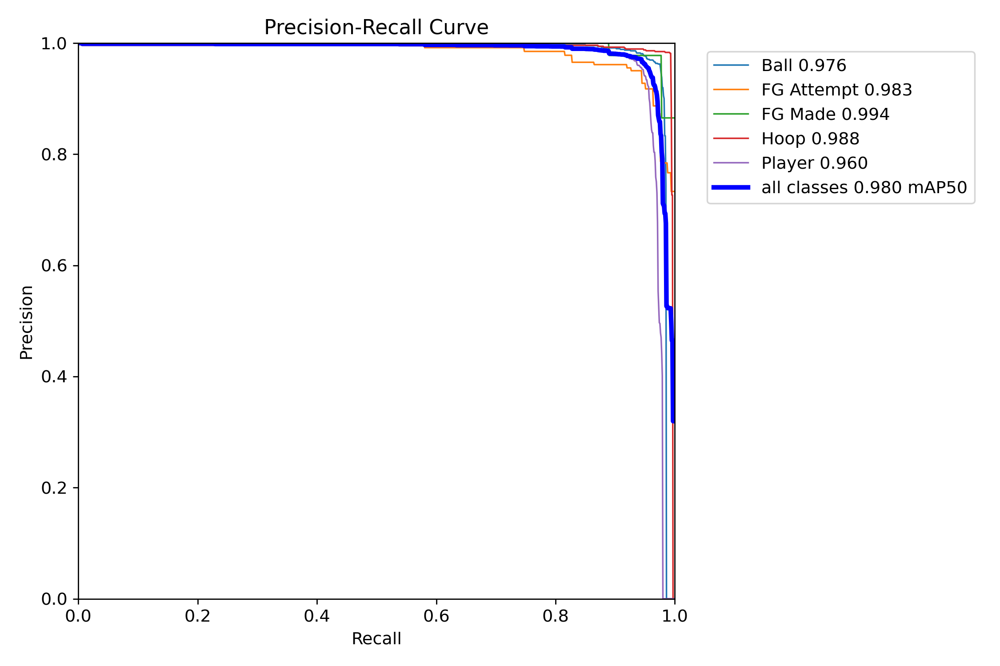

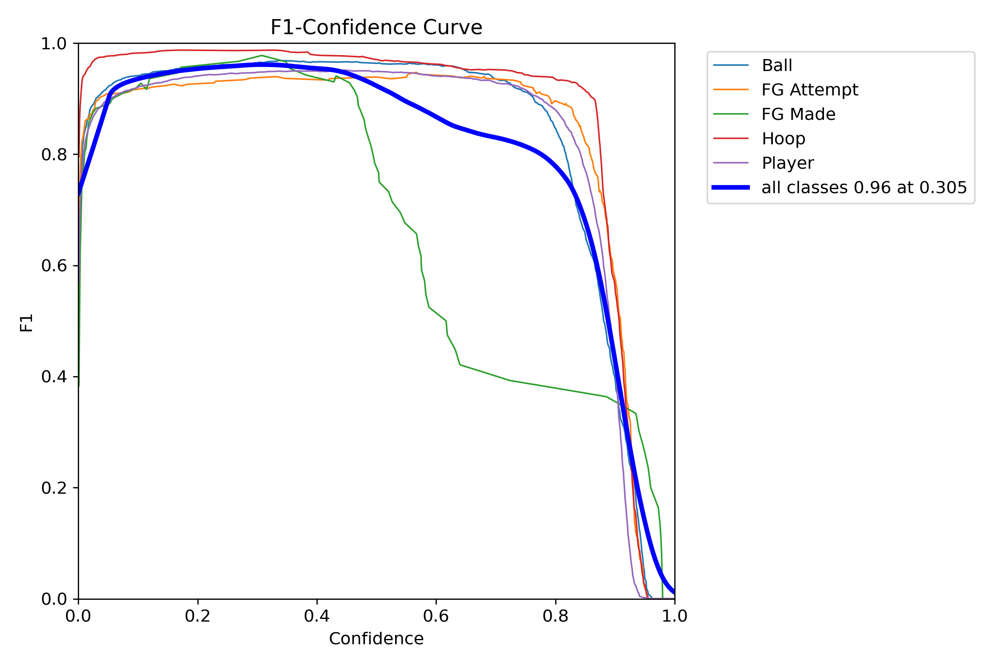

In [20]:
from IPython.display import Image, display

train_dir = Path(results.save_dir)
test_dir = Path(test_metrics.save_dir)

plots = [
    train_dir / "results.png",
    test_dir / "confusion_matrix_normalized.png",
    test_dir / "BoxPR_curve.png",
    test_dir / "BoxF1_curve.png"
]

for plot in plots:
    if plot.exists():
        display(Image(filename=str(plot), width=1000))
    else:
        print(f"Plot not found: {plot.name}")

## 10. Image Inference

Test the trained model on unseen test images and visualize
predicted bounding boxes, class labels, and confidence scores.

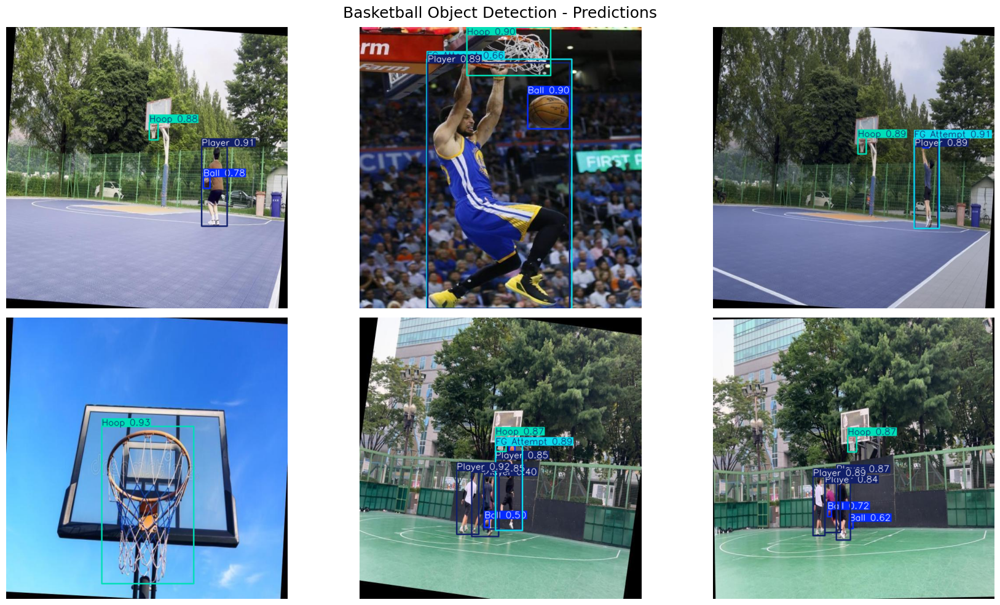

In [21]:
# Run inference on test images

test_images = sorted([
    p for p in (dataset_path / "test" / "images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

samples = random.Random(42).sample(test_images, 6)

predictions = best_model.predict(
    source=[str(p) for p in samples],
    conf=0.30,
    imgsz=640,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, prediction in zip(axes.flat, predictions):

    image = cv2.cvtColor(
        prediction.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(image)
    ax.axis("off")

plt.suptitle("Basketball Object Detection - Predictions", fontsize=18)
plt.tight_layout()
plt.show()

## 11. Video Inference & Object Tracking

Apply the trained YOLO26s model to a real basketball video
using ByteTrack for multi-object tracking and export
the annotated video.

In [22]:
from IPython.display import Video, display
import subprocess

# Locate the input video
video_dir = Path(
    "/kaggle/input/datasets/maimohammed128/basketball-test-video"
)

video_files = sorted(video_dir.rglob("*.mp4"))
assert video_files, "No MP4 video found."

video_path = video_files[0]

# Load the trained model
tracking_model = YOLO(
    "/kaggle/working/basketball/yolo26s_finetuned/weights/best.pt"
)

# Run object detection and tracking
tracking_results = tracking_model.track(
    source=str(video_path),
    tracker="bytetrack.yaml",
    conf=0.30,
    imgsz=640,
    device=0,
    stream=True,
    save=True,
    verbose=False,
    project="/kaggle/working/basketball",
    name="video_tracking",
    exist_ok=True
)

# Process all video frames
frame_count = 0

for result in tracking_results:
    frame_count += 1

print("Processed Frames:", frame_count)

# Locate the exported video
output_dir = Path(tracking_model.predictor.save_dir)

output_files = [
    p for p in output_dir.iterdir()
    if p.suffix.lower() in [".avi", ".mp4"]
]

assert output_files, "No exported video found."

# Convert to browser-compatible MP4
final_video = Path(
    "/kaggle/working/basketball_tracking.mp4"
)

subprocess.run([
    "ffmpeg", "-y",
    "-i", str(output_files[0]),
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    str(final_video)
], check=True, capture_output=True)

print("Saved Video:", final_video)

display(Video(str(final_video), embed=True, width=450))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 366ms
Prepared 1 package in 79ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Results saved to /kaggle/working/basketball/video_tracking
Processed Frames: 451
Saved Video: /kaggle/working/basketball_tracking.mp4


## 12. Model Export

Prepare the trained model weights for deployment
in a Streamlit application.

In [25]:
import shutil

# Export trained model weights
best_weights = Path(results.save_dir) / "weights" / "best.pt"

export_path = Path("/kaggle/working/best.pt")

shutil.copy2(best_weights, export_path)

print("Model exported:", export_path)
print(f"Model size: {export_path.stat().st_size / 1e6:.2f} MB")

Model exported: /kaggle/working/best.pt
Model size: 20.32 MB
